# Machine Learning for Membrane Development

This tutorial presents a reproducible workflow for machine learning-assisted membrane development using literature-derived membrane fabrication and performance data. The notebook integrates data preparation, domain-informed feature engineering, supervised modeling with ExtraTrees, SHAP-based interpretation, and Ax-based inverse design in a single pipeline .

The objective is not only to predict membrane performance, but also to identify the descriptor combinations that are most relevant to transport behavior and selective separation. In this way, the notebook serves as a practical companion to a review article on ML-enabled membrane development and materials discovery .

## Section 0. Setup 

This section imports the libraries required for data processing, machine learning, visualization, SHAP analysis, and Bayesian optimization. It also defines the global random seed and plotting style so that the workflow is reproducible and the figures are visually consistent throughout the notebook .

The imported tools reflect the main structure of the tutorial. `scikit-learn` is used for preprocessing, train-test splitting, hyperparameter search, and ExtraTrees regression; `shap` is used for post hoc model interpretation; and the Ax client is used for inverse design over selected fabrication variables.

In [ ]:
# For file handling and data manipulation
import os
import joblib
import numpy as np
import pandas as pd
import sys
import warnings

# For YAML configuration loading
try:
    import yaml
except ImportError:
    import subprocess
    print("Installing PyYAML...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyyaml"])
    import yaml

# For modeling and evaluation
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# For SHAP explanations (optional here; required later in SHAP section)
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# For inverse design (Ax is optional until Section 6)
try:
    from ax.api.client import Client
    from ax.api.configs import RangeParameterConfig, ChoiceParameterConfig
except Exception as exc:
    Client = None
    RangeParameterConfig = None
    ChoiceParameterConfig = None
    warnings.warn(
        f"Ax import skipped during setup: {exc}. "
        "You can still run Sections 1-5; fix Ax/PyTorch before Section 6.",
        RuntimeWarning,
    )

# ============================================================================
# CONFIGURATION SETUP: Load all settings from config.yaml
# ============================================================================

# Navigate to project root and add src to path for utl_config_loader
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
CODE_PATH = os.path.join(PROJECT_ROOT, "src")

if CODE_PATH not in sys.path:
    sys.path.insert(0, CODE_PATH)
    print(f"Added {CODE_PATH} to sys.path for module imports.")

# Load configuration from YAML file
from utl_config_loader import load_config, get_data_paths, get_model_dir, get_figures_dir, get_plotting_config

config = load_config(project_root=PROJECT_ROOT)
print(f"\nConfiguration loaded from: {config['_config_path']}")

# ============================================================================
# PLOTTING CONFIGURATION
# ============================================================================

plotting_cfg = config["plotting"]

# Extract and apply plotting settings
FONT_SIZE = plotting_cfg["font_size"]
FIG_SIZE = tuple(plotting_cfg["global_figure_size"])
DPI = plotting_cfg["dpi"]

# Apply matplotlib settings
plt.rcParams["font.size"] = FONT_SIZE
plt.rcParams["figure.figsize"] = FIG_SIZE
plt.rcParams["savefig.dpi"] = DPI

# Nicer plot defaults
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse, Rectangle

sns.set(style="whitegrid", context="talk")

# Create custom colormap from config
colormap_cfg = plotting_cfg["custom_colormap"]
custom_cmap = LinearSegmentedColormap.from_list(
    colormap_cfg["name"],
    colormap_cfg["colors"]
)

print(f"Plotting config applied: FIG_SIZE={FIG_SIZE}, FONT_SIZE={FONT_SIZE}, DPI={DPI}")

# ============================================================================
# MODELING CONFIGURATION
# ============================================================================

RANDOM_STATE = config["modeling"]["random_state"]
np.random.seed(RANDOM_STATE)

# ============================================================================
# DATA PATHS (from config)
# ============================================================================

data_paths = get_data_paths(config)
DATA_PATH = data_paths["dataset"]

## TODO do not hardcode these paths; instead, use config.yaml to specify them
lookup_by_align_column = data_paths.get("lookup_by_align_column", {})
CATION_PROP_PATH = lookup_by_align_column.get("S1_Cation")
ANION_PROP_PATH = lookup_by_align_column.get("S1_Anion")

if CATION_PROP_PATH is None or ANION_PROP_PATH is None:
    missing_lookup_keys = [
        key for key, value in {"S1_Cation": CATION_PROP_PATH, "S1_Anion": ANION_PROP_PATH}.items()
        if value is None
    ]
    raise KeyError(
        "Missing lookup path(s) in feature_engineering.lookups for: "
        f"{missing_lookup_keys}. Please define lookups with align_column values "
        "S1_Cation and S1_Anion in config.yaml."
    )

MODEL_PATH = get_model_dir(config)
FIGURES_DIR = get_figures_dir(config)

# Ensure output directories exist
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Data paths configured:")
print(f"  - Tutorial dataset: {os.path.basename(DATA_PATH)}")
print(f"  - Cation lookup: {os.path.basename(CATION_PROP_PATH)}")
print(f"  - Anion lookup: {os.path.basename(ANION_PROP_PATH)}")
print(f"  - Models directory: {MODEL_PATH}")
print(f"  - Figures output: {FIGURES_DIR}")


Added c:\GITHUB_NEW\ML-MEM-Review\src to sys.path for module imports.

Configuration loaded from: c:\GITHUB_NEW\ML-MEM-Review\config.yaml
Plotting config applied: FIG_SIZE=(14, 10), FONT_SIZE=20, DPI=300
Data paths configured:
  - Tutorial dataset: TutorialDataSet.xlsx
  - Cation lookup: cation_prop.xlsx
  - Anion lookup: anion_prop.xlsx
  - Models directory: c:\GITHUB_NEW\ML-MEM-Review\models
  - Figures output: c:\GITHUB_NEW\ML-MEM-Review\outputs/figures


## Section 1. Raw Dataset Loading & Overview

The starting dataset is loaded from the raw literature-curated membrane table and contains 278 rows and 36 columns, where each row corresponds to a membrane formulation-performance record extracted from the literature. The table includes bibliographic fields such as `DOI` and `Source_literature`, fabrication descriptors such as `Dope1_Monomer1_Name`, `Dope2_Monomer1_Mass`, and `Dope2_Polymerization_Time_min`, and target properties such as `Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}`, `salt_sol_Permeability_L_m2_h_bar`, and `solute1_Rejection`.

This raw table reflects the complexity of real membrane datasets. It combines chemistry, process conditions, and solute identity in one schema, which makes it suitable for machine learning but also requires careful preprocessing to manage mixed variable types, missing values, and repeated experimental patterns across literature sources.

The loading step is the entry point for the full workflow. From this table, the tutorial proceeds to cleaning, feature engineering, model training, interpretation, and inverse design.

In [2]:
# Load the dataset into a pandas DataFrame
df = pd.read_excel(DATA_PATH)

# Show the shape and first few rows of the dataset
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (278, 36)


,DOI,Source_literature,SampleID,Sup_mem_dope_polymer,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,...,Filtration_Time_min,Water_Permeation_Pressure_bar,Solute1_Type,Solute1_Name,Solute1_Feed_ppm,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},salt_sol_Permeability_L_m2_h_bar,solute1_Rejection
0,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-Na2SO4,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,Na_{2}SO_{4},2000,Na^{+},SO_{4}^{2-},47.9,24.0,98.47
1,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-MgCl2,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,MgCl_{2},2000,Mg^{2+},Cl^{-},47.9,47.0,10.00
2,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-NaCl,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,NaCl,2000,Na^{+},Cl^{-},47.9,40.2,14.20
3,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-K2SO4,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,K_{2}SO_{4},2000,K^{+},SO_{4}^{2-},47.9,NaN,NaN
4,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-CaCl2,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,CaCl_{2},2000,Ca^{2+},Cl^{-},47.9,45.9,6.90


### Data structure

The dataset is organized around interfacial polymerization and filtration descriptors. Fabrication variables include aqueous-phase and organic-phase components, treatment steps, polymerization time and temperature, compaction conditions, and filtration conditions, while solute descriptors identify the feed species and ionic composition through fields such as `Solute1_Name`, `S1_Cation`, and `S1_Anion` .

This structure is valuable because membrane performance is influenced not only by membrane chemistry, but also by process history and feed composition. A useful ML workflow should therefore preserve these distinctions instead of collapsing them into a small set of generic features .

### Missing Value and Duplicates identification

The dataset has been successfully loaded into a dataframe. Before proceeding, we can have an overview of the data quality by checking the number (and %) of missing values and duplicated entries. This step is important because missing values and duplicated entries can distort nearly every part of a machine learning workflow. Missing values may reduce the usable sample size, bias the dataset if they are not random, and cause many models or preprocessing steps to fail if they are not handled properly. Duplicates are just as problematic because they can artificially increase the influence of repeated observations, bias summary statistics, and give an overly optimistic impression of model performance during training and validation.

In a membrane research dataset, for example, duplicated experiments may make a certain formulation look more common or more successful than it really is, while missing process conditions or performance values can hide important structure?roperty relationships. By checking missingness and duplicates early, we can decide whether to impute, remove, merge, or otherwise correct the affected records before moving on to feature engineering and model training. In short, this quality check helps ensure that the model learns from reliable patterns rather than from artifacts in the data.

In [3]:
# Check the data types and missing values
print("\nData types and missing values:")
print("---"*30)
print(df.info())

# Check for duplicates
num_duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {num_duplicates}")


Data types and missing values:
------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278 entries, 0 to 277
Data columns (total 36 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   DOI                                              278 non-null    object 
 1   Source_literature                                278 non-null    object 
 2   SampleID                                         278 non-null    object 
 3   Sup_mem_dope_polymer                             278 non-null    object 
 4   Dope1_Monomer1_Name                              278 non-null    object 
 5   Dope1_Monomer1_Mass                              278 non-null    float64
 6   Dope1_Solvent1_Name                              278 non-null    object 
 7   Dope1_Solvent1_Mass                              278 non-null    

### i. Recognize missing?ata mechanisms

Before choosing an imputation strategy, it is important to understand **why** values are missing, because different mechanisms justify different handling methods.

- **Missing Completely at Random (MCAR)**  
  The probability that a value is missing is independent of both observed and unobserved data.  
  Example: A sensor randomly fails to log some measurements.  
  Typical handling: Simple methods (drop rows/columns if few, mean/median/mode imputation) are often acceptable.

- **Missing at Random (MAR)**  
  Missingness depends on other observed variables, but not on the missing value itself.  
  Example: Income is more likely to be missing for participants with lower education level.  
  Typical handling: More advanced, model?ased imputation (e.g. regression, k?N, multiple imputation).

- **Missing Not at Random (MNAR)**  
  Missingness depends on the unobserved (missing) values themselves.  
  Example: High?ncome individuals are less likely to report their income.  
  Typical handling: Specialized approaches (pattern?ixture or selection models) and sensitivity analyses; simple imputation can be seriously biased.

- **Systematic / structured missing data**  
  Entire features or blocks are missing due to design or collection issues.  
  Example: A sensor was never installed on certain devices, so that feature is absent for all of them.  
  Typical handling: Domain?nformed decisions (e.g. simple imputation, indicator/?roxyvariables, or dropping the feature/device subset).

For an accessible overview of MCAR, MAR, MNAR and examples, see the GeeksforGeeks article on *Types of Missing Data in Machine Learning*.

### ii. Choose a handling strategy

In practice, you typically combine these options:

- **Simple imputation**  
  Mean/median/mode or a fixed constant (good baseline for MCAR with low missingness).
- **Advanced imputation**  
  k?earest neighbors, regression?ased imputation, or multiple imputation (more suitable under MAR and when preserving relationships between variables matters).
- **Model?ased missing?ata methods**  
  Pattern?ixture or selection models for MNAR, often combined with domain knowledge and sensitivity analysis.

> We will apply the imputation later in the data-preprocessing just before the modelling 

For more implementation?riented discussion (including pros/cons and code snippets in Python), see the GeeksforGeeks guide *Handling Missing Values in Machine Learning*.
https://www.geeksforgeeks.org/data-analysis/handling-missing-values-machine-learning/ 



## TODO Duplicate identification and handling

In [4]:
# Load project-definition selections from config using the updated utl_config_loader API.
import utl_config_loader as cfg_loader

# Canonical target properties for modeling (KPIs)
configured_candidate_targets = cfg_loader.get_project_definition_target(config)

print("Configured targets from config (project_definition.target):")
for i, target_name in enumerate(configured_candidate_targets, start=1):
    print(f"  {i}. {target_name}")

# Keep only targets that are present in the loaded dataframe
candidate_targets = [t for t in configured_candidate_targets if t in df.columns]
missing_targets = [t for t in configured_candidate_targets if t not in df.columns]

print("\nAvailable targets in dataset:", candidate_targets)
if missing_targets:
    print("Targets listed in config but missing from dataset:", missing_targets)

if not candidate_targets:
    raise ValueError(
        "None of the configured project_definition.target columns were found in the dataset."
    )

# Raw columns to include for tutorial EDA/modeling subset
configured_cols_to_show = cfg_loader.get_project_definition_features(config)

print("\nConfigured features from config (project_definition.features):")
for i, col_name in enumerate(configured_cols_to_show, start=1):
    print(f"  {i}. {col_name}")

# Keep only configured columns that exist in the dataframe
available_feature_columns = [c for c in configured_cols_to_show if c in df.columns]
missing_feature_columns = [c for c in configured_cols_to_show if c not in df.columns]

if missing_feature_columns:
    print("\nproject_definition.features entries missing from dataset:", missing_feature_columns)

if not available_feature_columns:
    raise ValueError(
        "None of the configured project_definition.features columns were found in the dataset."
    )

# Append available targets to the selected feature columns (avoid duplicates)
cols_to_show = available_feature_columns + [
    t for t in candidate_targets if t not in available_feature_columns
]

# Filter the DataFrame to only include those columns for modeling and EDA
df_filtered = df[cols_to_show]
display(df_filtered.head())

# Separate numeric and categorical columns for later processing
df_numeric = df_filtered.select_dtypes(include=[np.number])
df_categorical = df_filtered.select_dtypes(include=["object"])

Configured targets from config (project_definition.target):
  1. Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}
  2. solute1_Rejection

Available targets in dataset: ['Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}', 'solute1_Rejection']

Configured features from config (project_definition.features):
  1. Dope1_Monomer1_Name
  2. Dope1_Monomer1_Mass
  3. Dope1_Solvent1_Name
  4. Dope1_Solvent1_Mass
  5. Dope1_Add1_Name
  6. Dope1_Add1_Mass
  7. Dope1_Treatment
  8. Dope1_Polymerization_Time_min
  9. Dope1_Polymerization_Temp_degC
  10. Dope1_Posttreat
  11. Dope2_Monomer1_Name
  12. Dope2_Monomer1_Mass
  13. Dope2_Solvent1_Name
  14. Dope2_Solvent1_Mass
  15. Dope2_Treatment
  16. Dope2_Polymerization_Time_min
  17. Dope2_Polymerization_Temp_degC
  18. Dope2_Posttreat
  19. Mem_Compaction_Pressure_bar
  20. Mem_Compaction_Time_hr
  21. Filtration_Area_cm2
  22. Filtration_Time_min
  23. Water_Permeation_Pressure_bar
  24. Solute1_Type
  25. Solute1_Name
  26. Solute1_Feed_ppm
  27. S

,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Treatment,Dope1_Polymerization_Time_min,Dope1_Polymerization_Temp_degC,Dope1_Posttreat,...,Filtration_Area_cm2,Filtration_Time_min,Water_Permeation_Pressure_bar,Solute1_Type,Solute1_Name,Solute1_Feed_ppm,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection
0,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,Na_{2}SO_{4},2000,Na^{+},SO_{4}^{2-},47.9,98.47
1,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,MgCl_{2},2000,Mg^{2+},Cl^{-},47.9,10.00
2,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,NaCl,2000,Na^{+},Cl^{-},47.9,14.20
3,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,K_{2}SO_{4},2000,K^{+},SO_{4}^{2-},47.9,NaN
4,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,CaCl_{2},2000,Ca^{2+},Cl^{-},47.9,6.90


## Section 2. Feature Engineering

The purpose of feature engineering is to convert the raw membrane table into an ML-ready representation while preserving physical meaning. In this notebook, the `featureengineering` function enriches the original dataframe with domain-informed descriptors and merges external ion property tables supplied through `CATIONPROPPATH` and `ANIONPROPPATH`.

This step is important because the raw input variables alone do not fully capture the chemistry of separation. By augmenting the table with cation and anion properties, the workflow links membrane formulation variables with solute-specific physicochemical information that is expected to influence permeability and rejection behavior.

In [5]:
from utl_feateng import*

In [6]:
"""
Section 2: Feature engineering

This section defines a function that:
- Selects a physically meaningful subset of features from the raw table.
- Handles missing values by dropping high-missing or constant columns.
- Returns an ML-ready feature matrix X and target vector y.

The feature list is inspired by your RFE-selected features and descriptor columns
used in the model-training notebooks.
"""
import pandas as pd
import numpy as np


# Enrich the main dataframe with domain-informed features
# Using config-driven paths: passes config to feature_engineering function
df_enriched = feature_engineering(
    df_filtered,
    config=config,  # Pass config to load paths automatically
    verbose=True,
)

df_enriched

Using config-driven feature engineering lookup specs for columns: ['S1_Cation', 'S1_Anion']

=== Checking merge columns for feature engineering ===

Column 'S1_Cation':
  - Present in main df: True
  - Present in lookup_S1_Cation: True
  Successfully merged lookup_S1_Cation on 'S1_Cation'

Column 'S1_Anion':
  - Present in main df: True
  - Present in lookup_S1_Anion: True
  Successfully merged lookup_S1_Anion on 'S1_Anion'
Created synthetic feature columns: ['total_dope_mass', 'aqueous_to_organic_monomer_ratio']


,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Treatment,Dope1_Polymerization_Time_min,Dope1_Polymerization_Temp_degC,Dope1_Posttreat,...,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection,S1_cat_cat_stoke_radius,S1_cat_cat_charge,S1_an_an_stoke_radius,S1_an_an_charge,total_dope_mass,aqueous_to_organic_monomer_ratio
0,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,Na^{+},SO_{4}^{2-},47.9,98.47,1.841,1,4.00,-2,0.001000,1.000000
1,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,Mg^{2+},Cl^{-},47.9,10.00,3.481,2,1.21,-1,0.001000,1.000000
2,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,Na^{+},Cl^{-},47.9,14.20,1.841,1,1.21,-1,0.001000,1.000000
3,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,K^{+},SO_{4}^{2-},47.9,NaN,1.249,1,4.00,-2,0.001000,1.000000
4,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,Ca^{2+},Cl^{-},47.9,6.90,3.109,2,1.21,-1,0.001000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
273,PIP,0.0010,H2O,0.970162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,Mg^{2+},Cl^{-},16.2,96.70,3.481,2,1.21,-1,0.031338,0.666667
274,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,Mg^{2+},Cl^{-},13.7,89.50,3.481,2,1.21,-1,0.039338,20.000000
275,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,Mg^{2+},Cl^{-},7.4,96.30,3.481,2,1.21,-1,0.039838,10.000000
276,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,Mg^{2+},Cl^{-},6.1,99.00,3.481,2,1.21,-1,0.040338,6.666667


### Enriched feature table

The enriched dataframe augments the original fabrication records with additional descriptor columns derived from cation and anion property datasets. These domain-informed variables help bridge membrane fabrication parameters with the underlying chemical characteristics of the transported or rejected solutes.

To keep this tutorial focused, we include only a limited set of ionic descriptors?uch as the Stokes radius?hich are known to strongly influence salt rejection. In practice, a much broader range of features can be incorporated. These may include monomer or polymer descriptors (e.g., chemical structure embeddings, surface properties), solvent properties (e.g., surface energy, heat of vaporization), and mixture-level properties (e.g., viscosity, surface tension, conductivity). Such data can be sourced from established databases or extracted from the literature.

At this stage, the objective is not yet model training, but rather the construction of a sufficiently rich descriptor space capable of capturing chemistry?rocess?erformance relationships. This step can be viewed as a form of physics-informed feature engineering. Accordingly, the enriched table serves as an intermediate scientific representation rather than a finalized machine learning input matrix.

### Variance and Correlation Filtering (Optional)

This filtering step is optional. It can be useful as a quick pre-modeling cleanup, but it is not required if the workflow already includes feature selection methods such as RFE, since those methods can indirectly remove features that are not helpful.

When enabled, near-constant features are removed first using a low-variance threshold, because variables that barely change across the dataset usually contribute little predictive information and can add noise. Strongly redundant numeric features can also be screened using correlation filtering, since highly correlated descriptors often carry overlapping information and may reduce model interpretability or add unnecessary redundancy.

In this tutorial, the filtering step is kept optional so the reader can choose between a lighter preprocessing pipeline and a more explicit feature selection approach. If RFE or another embedded selection method is used later, that step may already handle much of the redundancy, making this preliminary filter less necessary.

In [7]:
# After enrichment, we have 30+ features. We can apply the same variance and correlation filtering as before to get a more manageable set for modeling.
# Using config-driven threshold from feature_engineering section
variance_threshold = config["feature_engineering"]["low_variance_threshold"]

df_enriched_filtered, _ = remove_low_variance_columns(
    df_enriched, 
    exclude_columns=candidate_targets,
    variance_threshold=variance_threshold
)

print(f"Applied variance threshold: {variance_threshold}")

# Have a look at the filtered enriched dataframe before modeling
df_enriched_filtered

Removed 16 low variance columns (threshold: 1e-09):
  - Dope1_Solvent1_Name: 'H2O' (dtype: object)
  - Dope1_Treatment: 'Immersion' (dtype: object)
  - Dope1_Polymerization_Time_min: variance=0.000000 (dtype: float64)
  - Dope1_Polymerization_Temp_degC: variance=0.000000 (dtype: int64)
  - Dope1_Posttreat: 'Rubber rolling ' (dtype: object)
  - Dope2_Monomer1_Name: 'TMC' (dtype: object)
  - Dope2_Treatment: 'Immersion' (dtype: object)
  - Dope2_Polymerization_Temp_degC: variance=0.000000 (dtype: int64)
  - Dope2_Posttreat: 'Air dried' (dtype: object)
  - Mem_Compaction_Pressure_bar: variance=0.000000 (dtype: int64)
  - Mem_Compaction_Time_hr: variance=0.000000 (dtype: int64)
  - Filtration_Area_cm2: variance=0.000000 (dtype: float64)
  - Filtration_Time_min: variance=0.000000 (dtype: int64)
  - Water_Permeation_Pressure_bar: variance=0.000000 (dtype: int64)
  - Solute1_Type: 'Salt' (dtype: object)
  - Solute1_Feed_ppm: variance=0.000000 (dtype: int64)
Applied variance threshold: 1e-09


,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope2_Monomer1_Mass,Dope2_Solvent1_Name,Dope2_Solvent1_Mass,Dope2_Polymerization_Time_min,Solute1_Name,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection,S1_cat_cat_stoke_radius,S1_cat_cat_charge,S1_an_an_stoke_radius,S1_an_an_charge,total_dope_mass,aqueous_to_organic_monomer_ratio
0,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,Na_{2}SO_{4},Na^{+},SO_{4}^{2-},47.9,98.47,1.841,1,4.00,-2,0.001000,1.000000
1,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,MgCl_{2},Mg^{2+},Cl^{-},47.9,10.00,3.481,2,1.21,-1,0.001000,1.000000
2,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,NaCl,Na^{+},Cl^{-},47.9,14.20,1.841,1,1.21,-1,0.001000,1.000000
3,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,K_{2}SO_{4},K^{+},SO_{4}^{2-},47.9,NaN,1.249,1,4.00,-2,0.001000,1.000000
4,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,CaCl_{2},Ca^{2+},Cl^{-},47.9,6.90,3.109,2,1.21,-1,0.001000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
273,PIP,0.0010,0.970162,SLS,0.028838,0.0015,n-Hexane,0.9985,0.083333,MgCl_{2},Mg^{2+},Cl^{-},16.2,96.70,3.481,2,1.21,-1,0.031338,0.666667
274,PIP,0.0100,0.961162,SLS,0.028838,0.0005,n-Hexane,0.9995,0.083333,MgCl_{2},Mg^{2+},Cl^{-},13.7,89.50,3.481,2,1.21,-1,0.039338,20.000000
275,PIP,0.0100,0.961162,SLS,0.028838,0.0010,n-Hexane,0.9990,0.083333,MgCl_{2},Mg^{2+},Cl^{-},7.4,96.30,3.481,2,1.21,-1,0.039838,10.000000
276,PIP,0.0100,0.961162,SLS,0.028838,0.0015,n-Hexane,0.9985,0.083333,MgCl_{2},Mg^{2+},Cl^{-},6.1,99.00,3.481,2,1.21,-1,0.040338,6.666667


### Why feature filtering matters

Several fabrication columns are effectively constant or nearly constant across the dataset, such as some treatment temperatures, compaction conditions, and feed conditions. Removing these low-variance variables prevents the model from carrying uninformative predictors and reduces the dimensionality of the encoded feature space.

At the same time, the retained variables still span multiple descriptor classes, including monomer identity, additive identity, composition, polymerization time, solvent information, and ion descriptors. This balance between reduction and retention is essential for tabular membrane ML, where the number of samples is limited relative to the number of possible descriptors.

## Section 3. Exploratory Data Analysis

Before model training, it is useful to inspect the structure of the filtered dataset. Correlation analysis among numeric variables helps identify redundancy, dominant process axes, and possible coupling between fabrication descriptors and target behavior.

Exploratory analysis also acts as a quality-control step. If numeric descriptors are weakly informative, strongly collinear, or sparsely populated, that affects both model choice and the confidence that can be placed in subsequent interpretation.

Saved target distributions to c:\GITHUB_NEW\ML-MEM-Review\outputs/figures


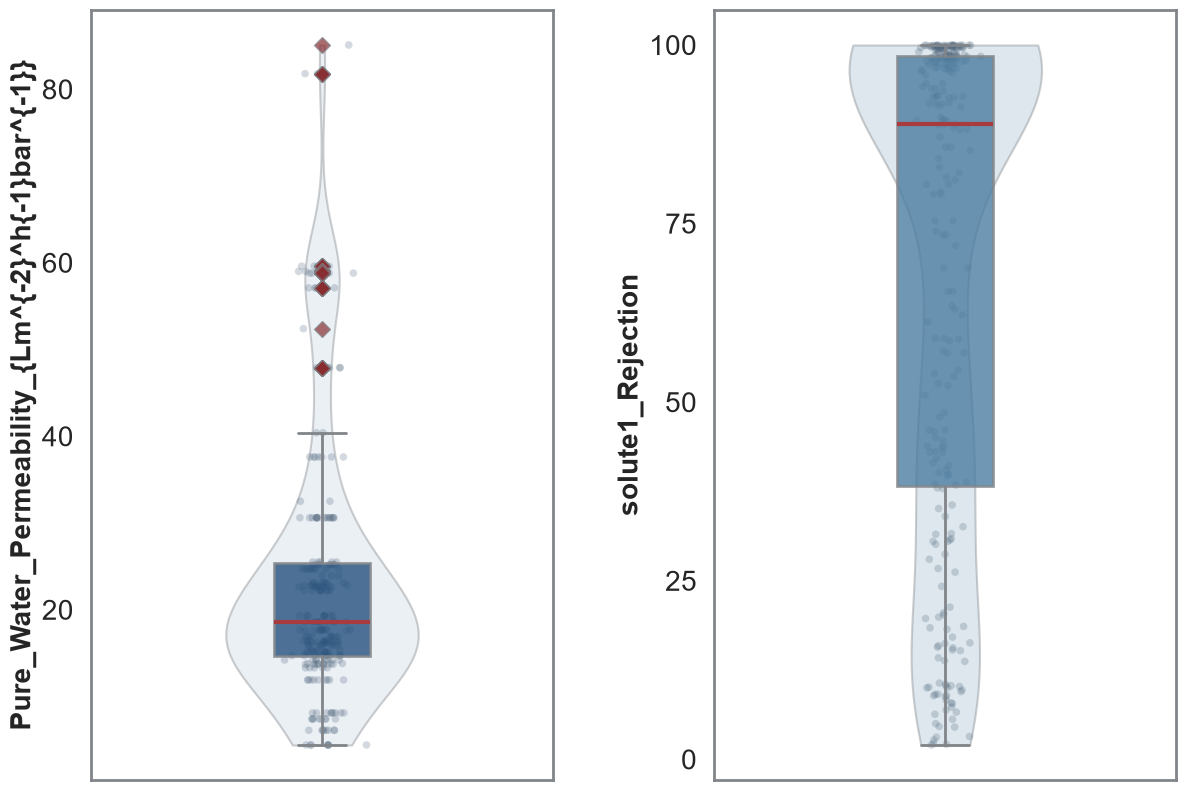

In [8]:
from utl_eda import *
from utl_fileIO import file_io

fig, axes = plot_target_distributions(
    df_enriched_filtered,
    candidate_targets,
    fig_size=FIG_SIZE,
)

file_io("save", "figure", FIGURES_DIR, "target_distributions.png", data=fig)
print(f"Saved target distributions to {FIGURES_DIR}")

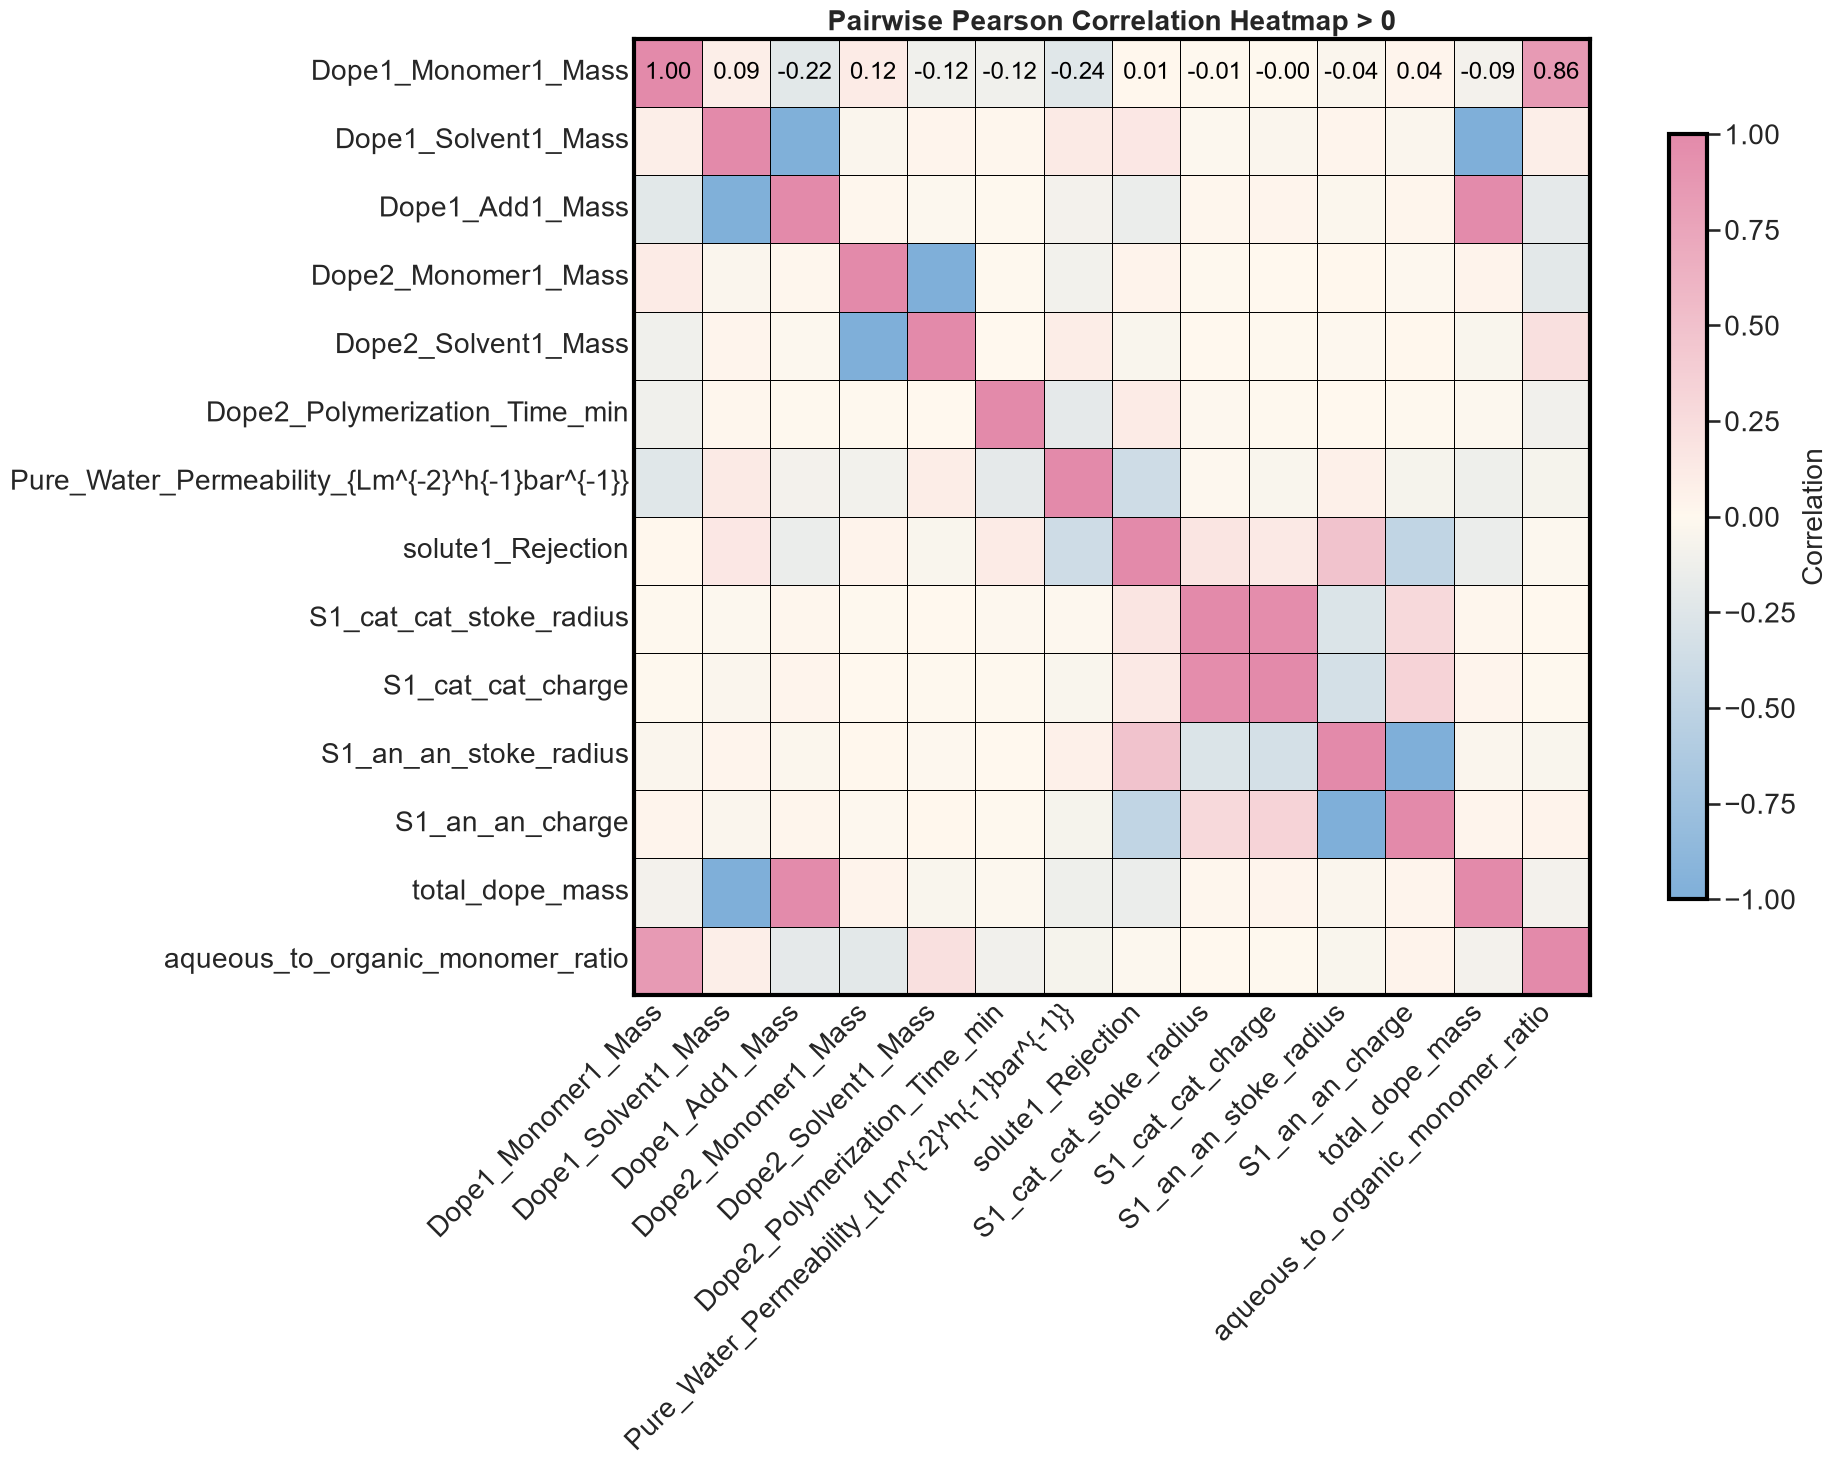

c:\Users\Kai Qi Yan\anaconda3\envs\MLEnv_Brine\Lib\site-packages\seaborn\matrix.py:260: FutureWarning:

Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior



<Figure size 1400x1000 with 0 Axes>

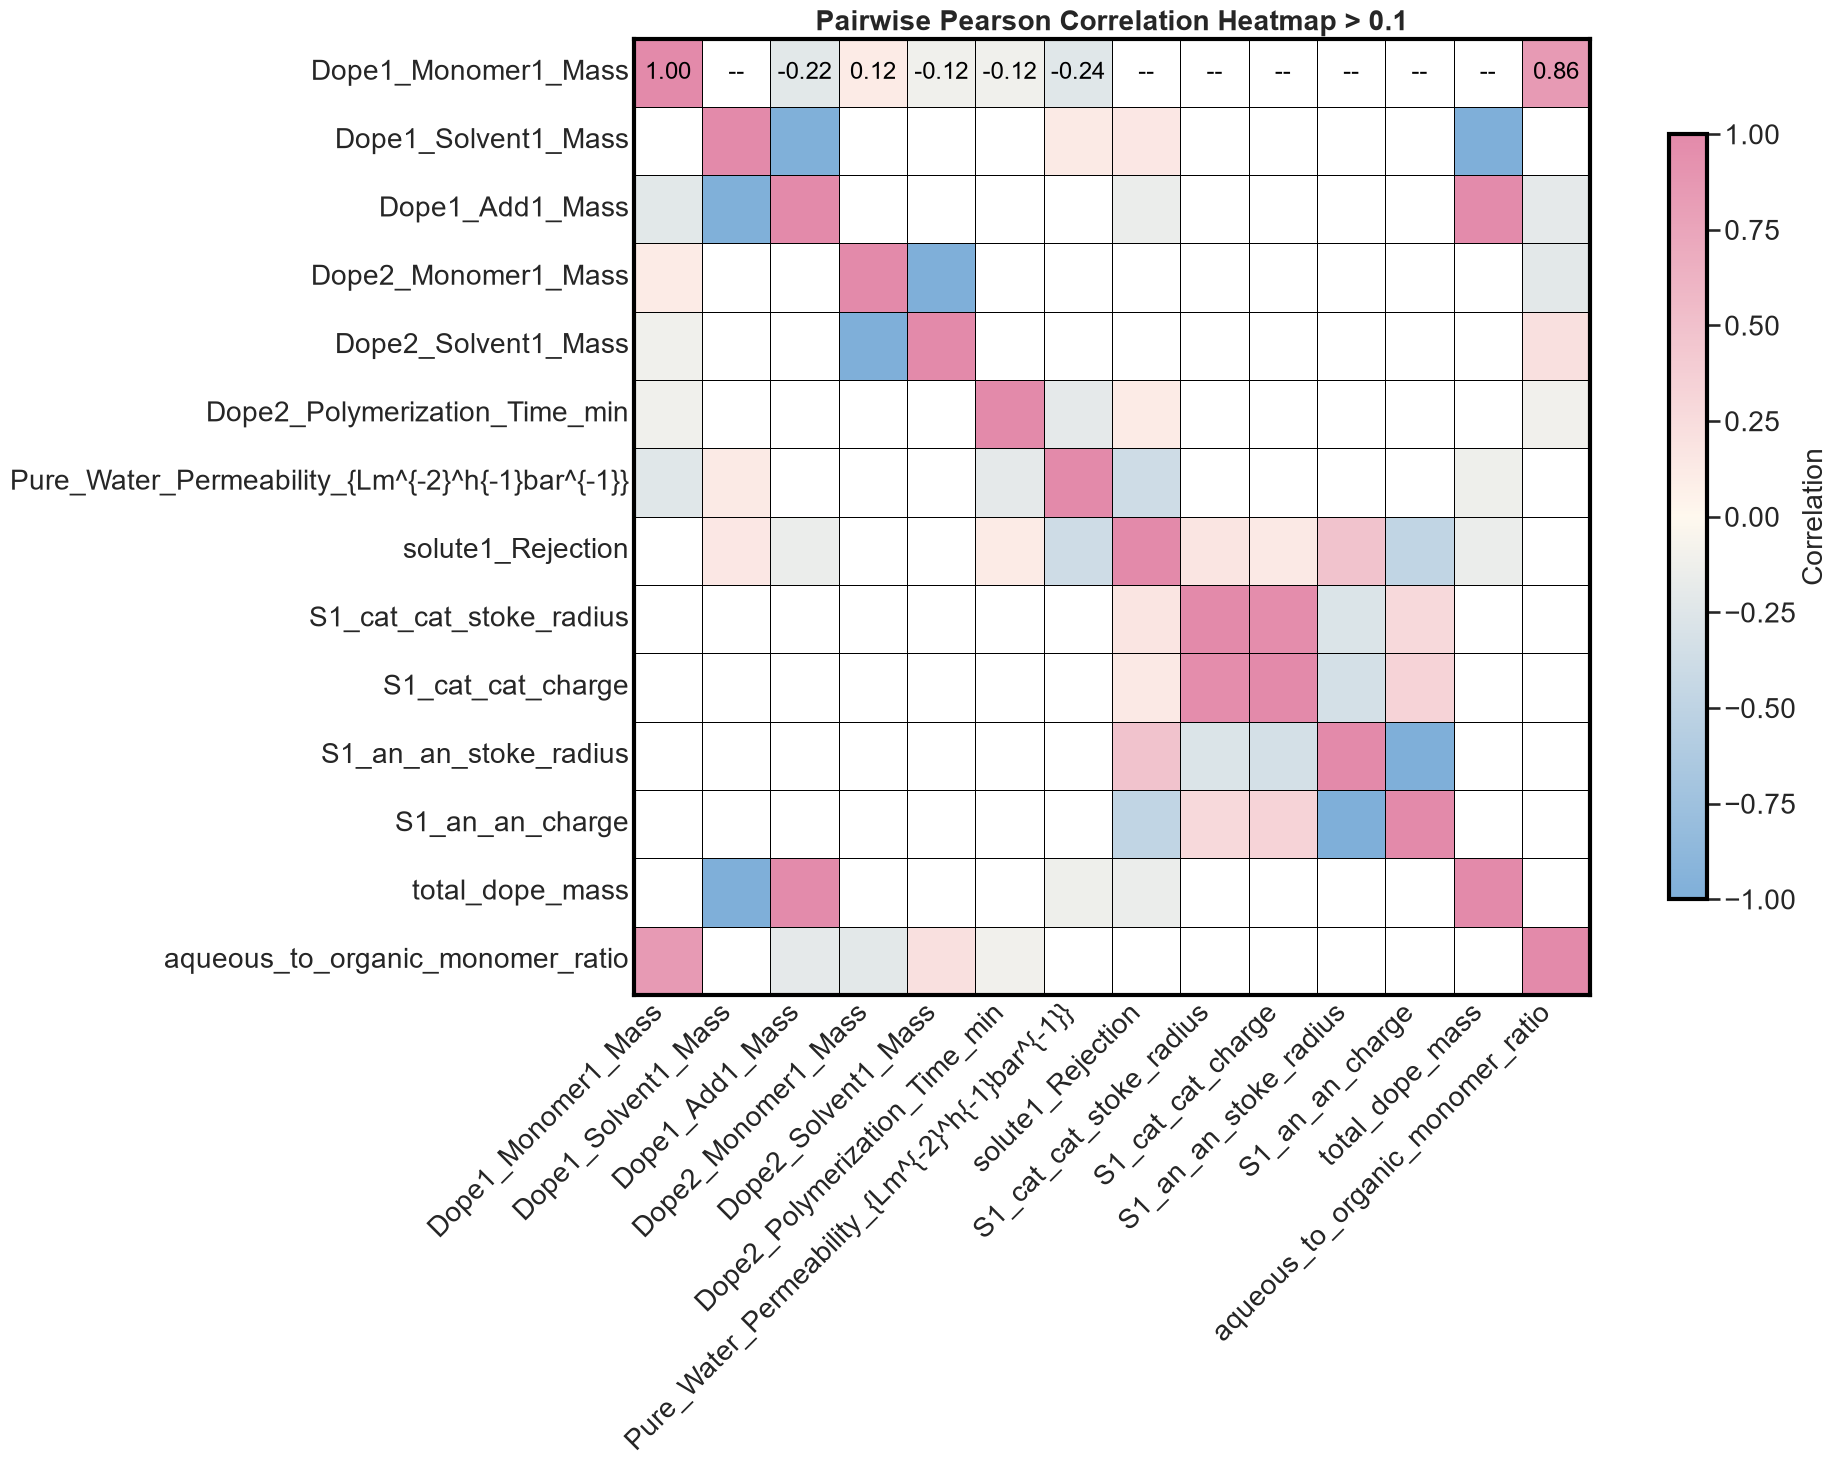

Generated heatmaps with thresholds: [0, 0.1]


<Figure size 1400x1000 with 0 Axes>

In [9]:
# Compute and plot the Pearson correlation heatmap for the numeric features in the enriched dataframe, using different thresholds to focus on stronger correlations.

from utl_fileIO import file_io

df_enriched_numeric = df_enriched_filtered.select_dtypes(include=[np.number]) # Select only numeric columns for correlation analysis

# Use thresholds from config
correlation_thresholds = config["data_analysis"]["correlation_thresholds"]

for threshold in correlation_thresholds:
    corr_matrix = compute_and_plot_pearson_heatmap(df_enriched_numeric, threshold=threshold, fig_size=[1.5 * x for x in FIG_SIZE])
    heatmap_fig = plt.gcf()
    file_io("save", "figure", FIGURES_DIR, f"pearson_heatmap_threshold_{threshold}.png", data=heatmap_fig)

print(f"Generated heatmaps with thresholds: {correlation_thresholds}")

### Interpreting the correlation structure

The correlation matrix should be read as a descriptive summary rather than as a mechanistic proof. Strong pairwise correlations may arise from experimental design conventions in the literature as much as from true physical coupling, while weak linear correlations do not imply that a nonlinear model will be uninformative.

For this reason, the tutorial proceeds to a tree-based ensemble model. ExtraTrees can capture nonlinear and interaction effects that are likely to matter in membrane datasets, especially when recipe variables and solute descriptors interact in non-additive ways.

In [10]:
# Load modeling features from config.yaml to keep training inputs centralized and consistent.
base_features = config.get("features_to_model", [])

if not base_features:
    raise ValueError(
        "Missing or empty config key: features_to_model in config.yaml."
    )

# Optional visibility check against the enriched dataframe at this stage
missing_base_features = [f for f in base_features if f not in df_enriched_filtered.columns]
if missing_base_features:
    print("Features listed in config but missing from df_enriched_filtered:", missing_base_features)

print(f"Using {len(base_features)} base features from config.yaml")
for i, feature_name in enumerate(base_features, start=1):
    print(f"  {i}. {feature_name}")

Features listed in config but missing from df_enriched_filtered: ['S1_cat_stoke_radius', 'S1_cat_charge', 'S1_an_stoke_radius', 'S1_an_charge']
Using 15 base features from config.yaml
  1. Dope1_Monomer1_Name
  2. Dope1_Monomer1_Mass
  3. Dope1_Solvent1_Mass
  4. Dope1_Add1_Name
  5. Dope1_Add1_Mass
  6. Dope2_Monomer1_Mass
  7. Dope2_Solvent1_Name
  8. Dope2_Solvent1_Mass
  9. Dope2_Polymerization_Time_min
  10. Solute1_Name
  11. S1_Cation
  12. S1_cat_stoke_radius
  13. S1_cat_charge
  14. S1_an_stoke_radius
  15. S1_an_charge


In [11]:
from sklearn.base import clone
from utl_model_arch import PipelineConfig, build_training_pipeline, get_hyperparameter_space, build_model_pipeline

modeling_cfg = config["modeling"]
pipeline_cfg_dict = modeling_cfg.get("pipeline", {})
hyperparameter_space = get_hyperparameter_space(config)

pipeline_template = build_training_pipeline(PipelineConfig(**pipeline_cfg_dict))
print("Pipeline template built via utl_model_arch.PipelineConfig")

print("Hyperparameter space keys:", list(hyperparameter_space.keys()))

Pipeline template built via utl_model_arch.PipelineConfig
Hyperparameter space keys: ['model__n_estimators', 'model__max_depth', 'model__min_samples_leaf', 'model__max_features']


## Section 4. Predictive Modeling with ExtraTrees


After feature enrichment, the notebook constructs an ML-ready feature matrix and target vector by selecting a physically meaningful subset of columns and removing features with excessive missingness or negligible variance. This is the role of `buildfeaturetable`, which converts the enriched dataframe into `X` and `y` for a chosen target property.

This filtering step improves both statistical stability and interpretability. In small literature-derived datasets, retaining every possible column usually increases noise and leakage risk, whereas a curated feature set produces more reliable training behavior and more defensible interpretation.

The core predictive model in this tutorial is an `ExtraTreesRegressor` embedded in a preprocessing pipeline. This choice is motivated by three practical advantages: the method can model nonlinear relationships, it handles mixed descriptor types after one-hot encoding, and it is generally effective on small-to-medium tabular datasets such as literature-curated membrane datasets.

The training workflow uses a `ColumnTransformer` to one-hot encode categorical variables while passing numerical variables through unchanged. This ensures that preprocessing is learned on the training data only and then applied consistently to held-out samples, which is essential for avoiding information leakage.

### Train-test strategy and tuning

The model is trained using an explicit train-test split so that predictive performance can be evaluated on unseen samples. When enabled, `RandomizedSearchCV` is used to tune hyperparameters such as the number of estimators, tree depth, minimum leaf size, and feature subsampling strategy.

This setup reflects a practical objective: not only to obtain a well-performing model, but also to build a stable surrogate that can later be interpreted with SHAP and queried during inverse design. In membrane development, such a surrogate is valuable because it can guide formulation choices before expensive experiments are performed.

### Model performance

Model performance is summarized using \(R^2\), RMSE, and MAE on both training and test sets. Reporting both train and test metrics is important because it helps distinguish useful learning from simple overfitting, which is a common risk in small materials datasets with many encoded variables.

A good result in this context is not only a high test-set score, but also a reasonable gap between training and test performance. That pattern suggests that the model is capturing transferable structure-property relationships rather than memorizing literature-specific combinations of descriptors.



=== Modeling target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Initial feature count: 11
Initial sample count: 275
Final feature count: 11

=== Reusing existing model for target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Loading model from: c:\GITHUB_NEW\ML-MEM-Review\models\Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}_extratrees_regressor.pkl

Final performance on train/test split:
Train R²   = 0.9597
Train RMSE = 3.3226
Train MAE  = 1.2015
Test R²   = 0.9009
Test RMSE = 4.0136
Test MAE  = 1.6400

Performance for target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}
Train R²   = 0.9597
Train RMSE = 3.3226
Train MAE  = 1.2015
Test R²   = 0.9009
Test RMSE = 4.0136
Test MAE  = 1.6400


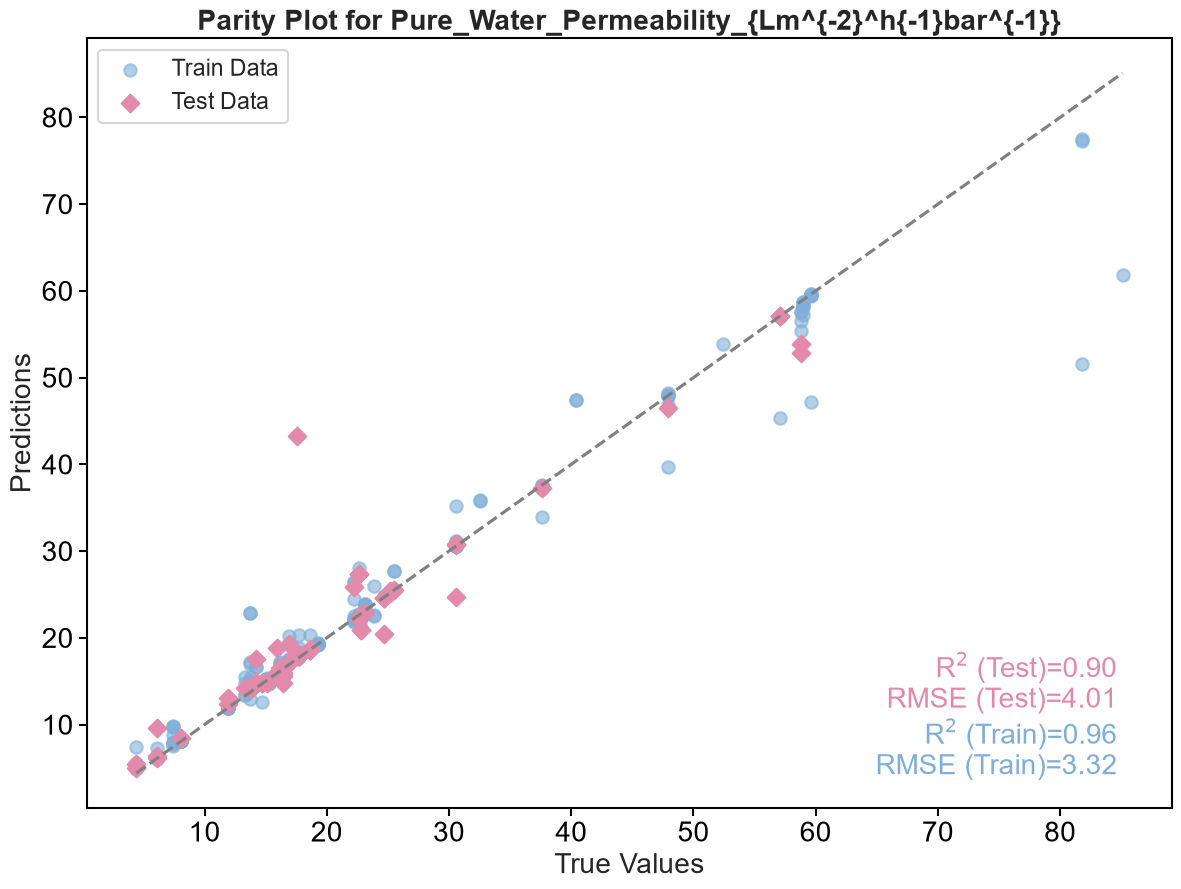


=== Modeling target: solute1_Rejection ===
Initial feature count: 11
Initial sample count: 276
Final feature count: 11

=== Reusing existing model for target: solute1_Rejection ===
Loading model from: c:\GITHUB_NEW\ML-MEM-Review\models\solute1_Rejection_extratrees_regressor.pkl

Final performance on train/test split:
Train R²   = 0.9998
Train RMSE = 0.4912
Train MAE  = 0.0592
Test R²   = 0.8740
Test RMSE = 12.1513
Test MAE  = 7.5450

Performance for target: solute1_Rejection
Train R²   = 0.9998
Train RMSE = 0.4912
Train MAE  = 0.0592
Test R²   = 0.8740
Test RMSE = 12.1513
Test MAE  = 7.5450


<Figure size 1400x1000 with 0 Axes>

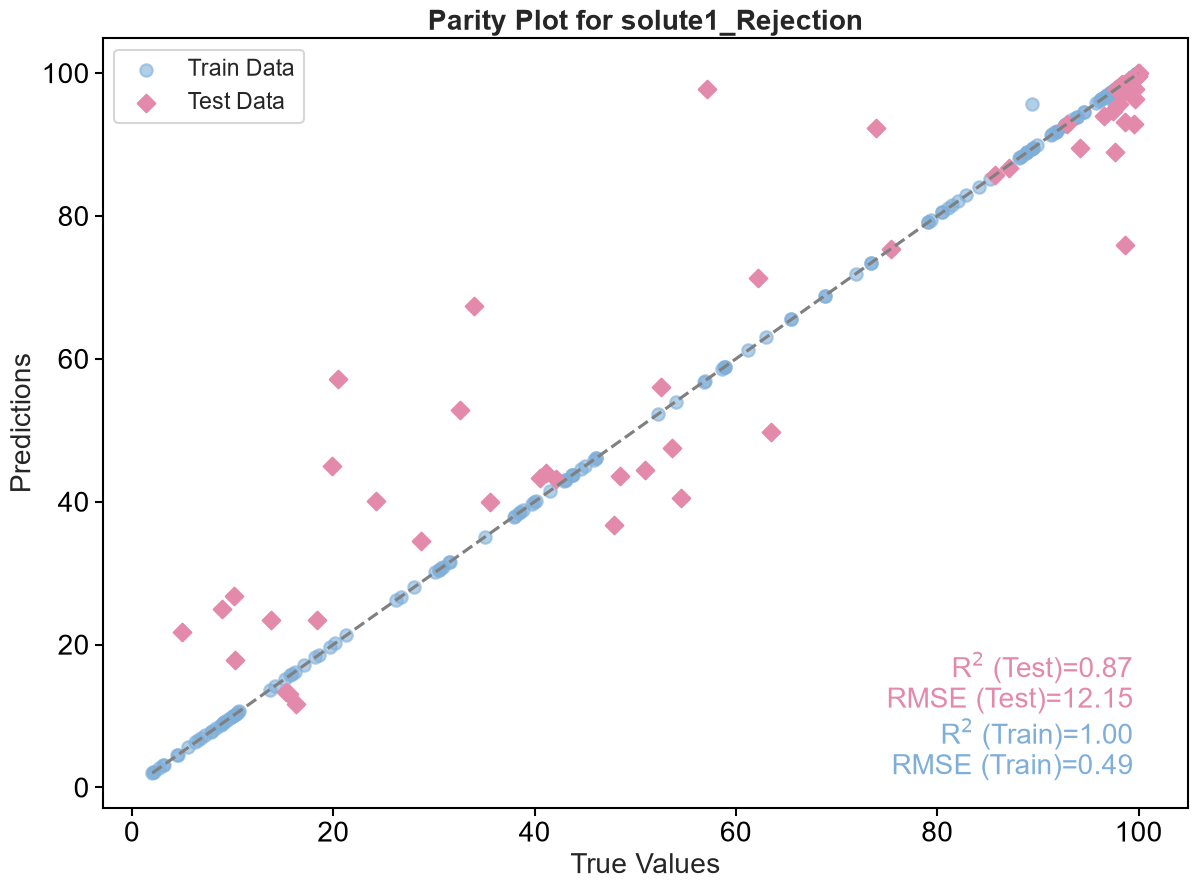

Completed modeling for 2 targets


<Figure size 1400x1000 with 0 Axes>

In [12]:
import importlib
import utl_modelling
from utl_fileIO import file_io

# Reload to ensure the notebook uses the latest src/utl_modelling.py changes.
utl_modelling = importlib.reload(utl_modelling)
train_model = utl_modelling.train_model
evaluate_and_plot_parity = utl_modelling.evaluate_and_plot_parity

# Loop over candidate targets
for target in candidate_targets:
    print(f"\n=== Modeling target: {target} ===")

    # Clone to keep each target run isolated from fitted state.
    model_pipeline = clone(pipeline_template)

    pipe, X_train, X_test, y_train, y_test = train_model(
        df=df_enriched_filtered,
        target=target,
        pipeline=model_pipeline,
        config_path=config["_config_path"],
        force_retrain=False,
        param_dist_override=hyperparameter_space,
    )

    # Predict on train and test
    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)

    evaluate_and_plot_parity(
        target=target,
        y_train=y_train,
        y_pred_train=y_pred_train,
        y_test=y_test,
        y_pred_test=y_pred_test,
        fig_size=FIG_SIZE,
    )

    safe_target = "".join(ch if ch.isalnum() else "_" for ch in str(target)).strip("_")
    parity_fig = plt.gcf()
    file_io("save", "figure", FIGURES_DIR, f"parity_{safe_target}.png", data=parity_fig)

print(f"Completed modeling for {len(candidate_targets)} targets")


### Parity analysis

Parity plots provide a compact visual summary of model quality by comparing predicted and observed target values. In this notebook, `evaluateandplotparity` is used to assess how closely the fitted ExtraTrees model reproduces measured membrane performance across both training and test subsets.

In membrane ML, parity plots are especially helpful because they reveal more than a single score. They can show systematic bias, target-range compression, or poor performance in specific regions such as highly permeable or highly selective membranes.

### Reading the parity plot

A useful parity plot should show that most points lie near the diagonal while preserving spread across the full target range. Deviations from the diagonal may indicate limited representation of certain formulation regimes, noisy literature measurements, or unresolved descriptor gaps in the current feature space.

This kind of diagnostic matters scientifically. If the model performs well only in a narrow region of the design space, then its predictions and later inverse-design recommendations should be interpreted as local hypotheses rather than global design rules.

## Section 5. SHAP-Based Model Interpretation

Predictive accuracy alone does not reveal why the model behaves as it does. To make the workflow scientifically useful, the notebook applies SHAP analysis through `shapexplaintarget`, which computes feature-level contributions using `shap.TreeExplainer` on the fitted ExtraTrees model.

This step converts the model from a black-box predictor into a source of interpretable hypotheses. By ranking transformed features and visualizing their effects across many samples, SHAP helps identify which fabrication and solute descriptors are most strongly associated with the target response.

In [13]:
from utl_shap import*

### Global SHAP summary

The SHAP beeswarm plot summarizes how each encoded feature contributes to model output across the dataset. Features near the top of the ranking are those with the strongest overall influence on prediction, while the color pattern indicates whether high or low values of a descriptor tend to increase or decrease the target.

For membrane science, this kind of plot is especially useful because it combines statistical importance with directional information. It can therefore highlight whether the model is associating higher permeability or higher rejection with particular monomers, additives, solute properties, or process conditions.

### Aggregate feature importance

The SHAP bar plot complements the beeswarm figure by ranking features according to their average absolute contribution. This provides a cleaner global summary of which encoded descriptors dominate the model, even when the direction of effect varies across samples.

These rankings should be interpreted cautiously. SHAP identifies influential predictors within the trained model, but importance is not the same as causality, and literature-derived datasets can reflect reporting practices and correlated design choices as well as underlying membrane physics.

"""
Section 4: SHAP interpretation

This section:
- Loads the trained ExtraTrees pipeline for each target from disk.
- Extracts preprocessing and model steps from the pipeline.
- Applies SHAP TreeExplainer to transformed features.
- Produces SHAP summary plots to interpret feature effects.

Tutorial tip:
Use the beeswarm plot for directionality (high/low values push prediction up/down),
and the bar plot for quick global ranking of important features.
"""


=== SHAP interpretation for target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Initial feature count: 11
Initial sample count: 275
Final feature count: 11
Loaded model from: c:\GITHUB_NEW\ML-MEM-Review\models\Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}_extratrees_regressor.pkl


C:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:182: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



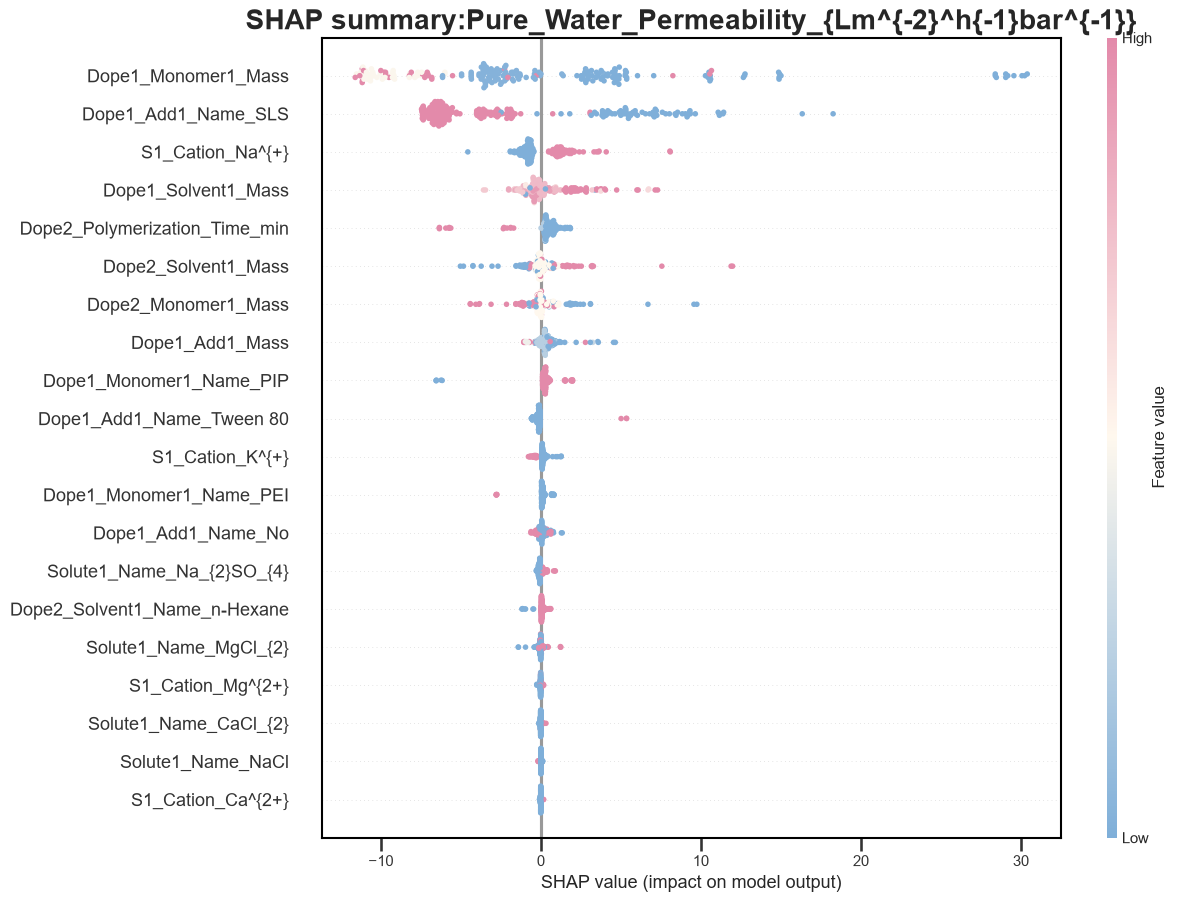

C:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:204: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



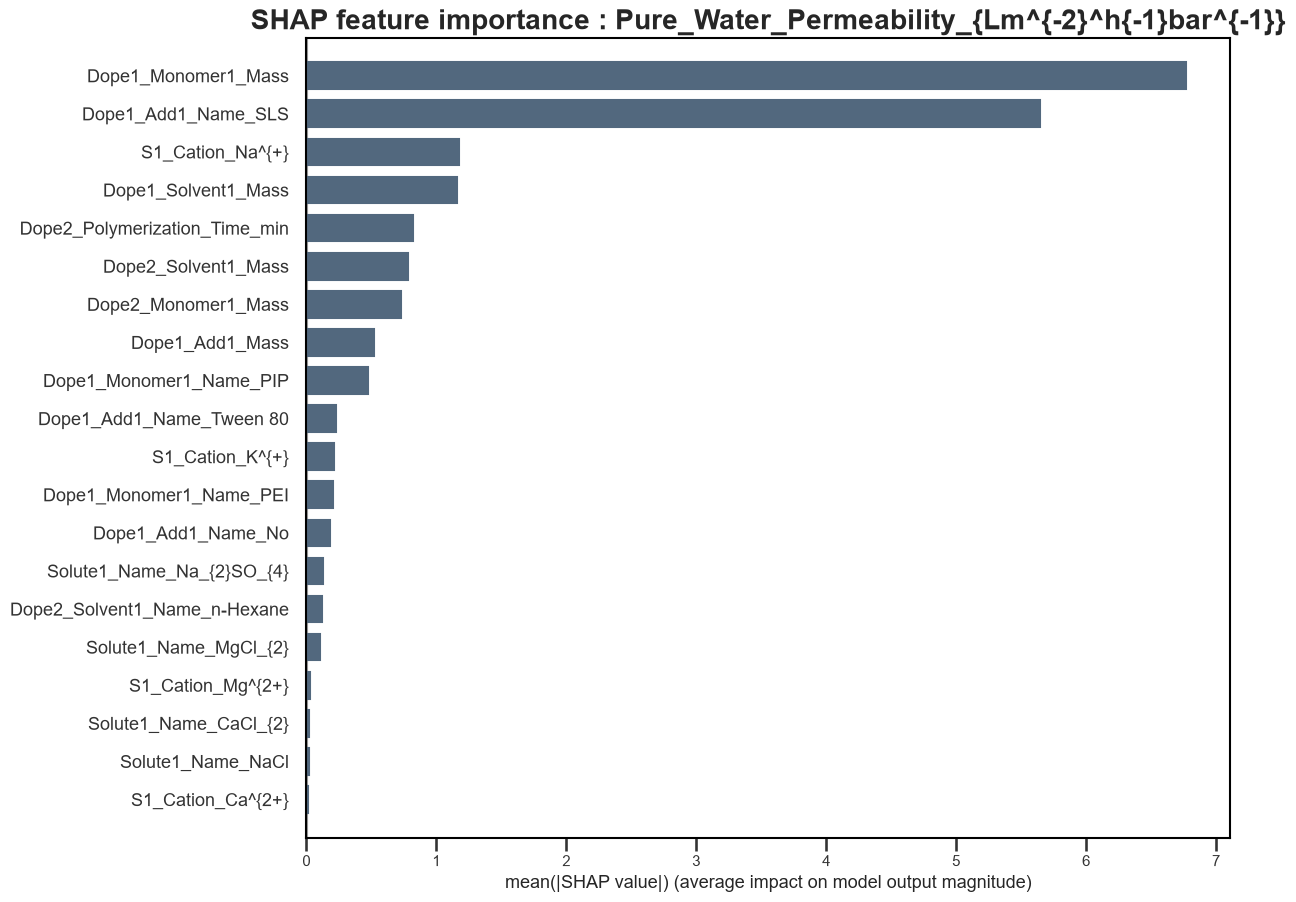


=== SHAP interpretation for target: solute1_Rejection ===
Initial feature count: 11
Initial sample count: 276
Final feature count: 11
Loaded model from: c:\GITHUB_NEW\ML-MEM-Review\models\solute1_Rejection_extratrees_regressor.pkl


C:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:182: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



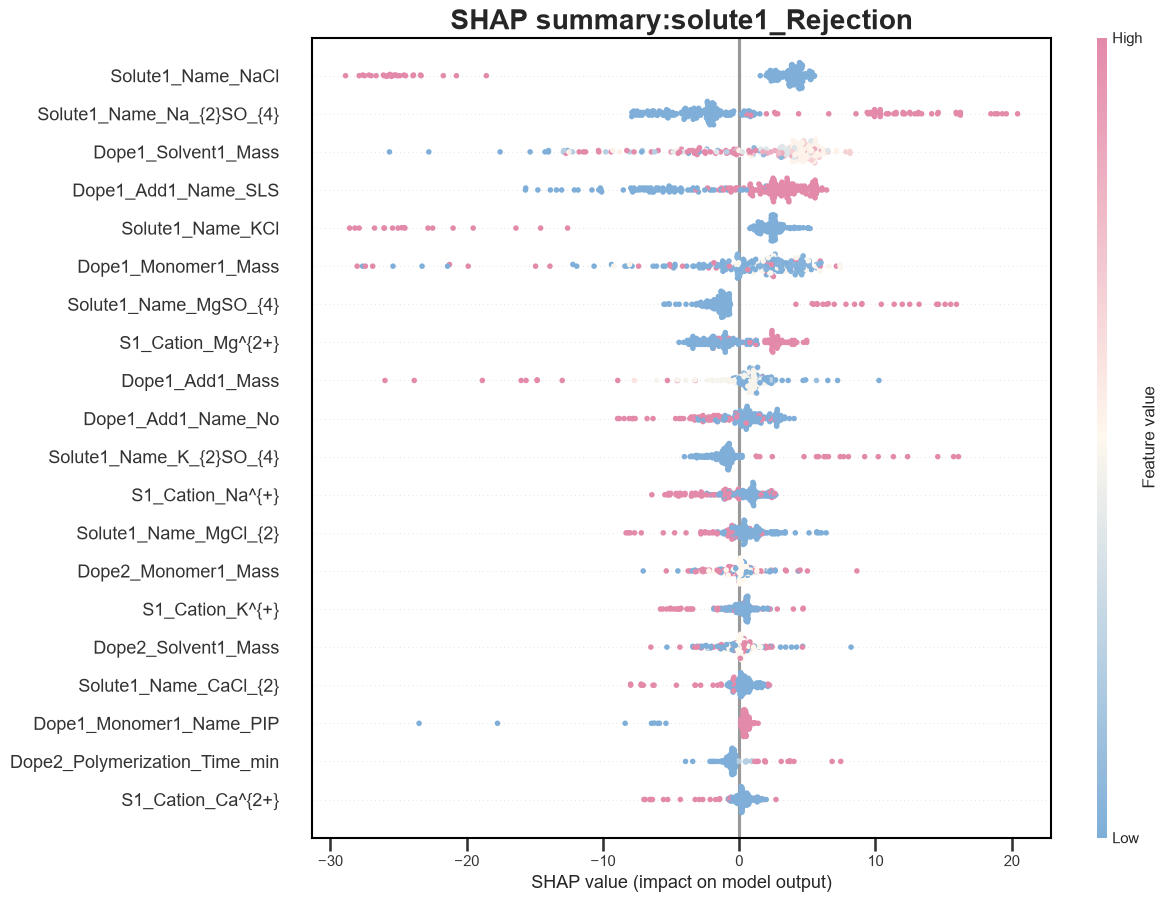

C:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:204: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



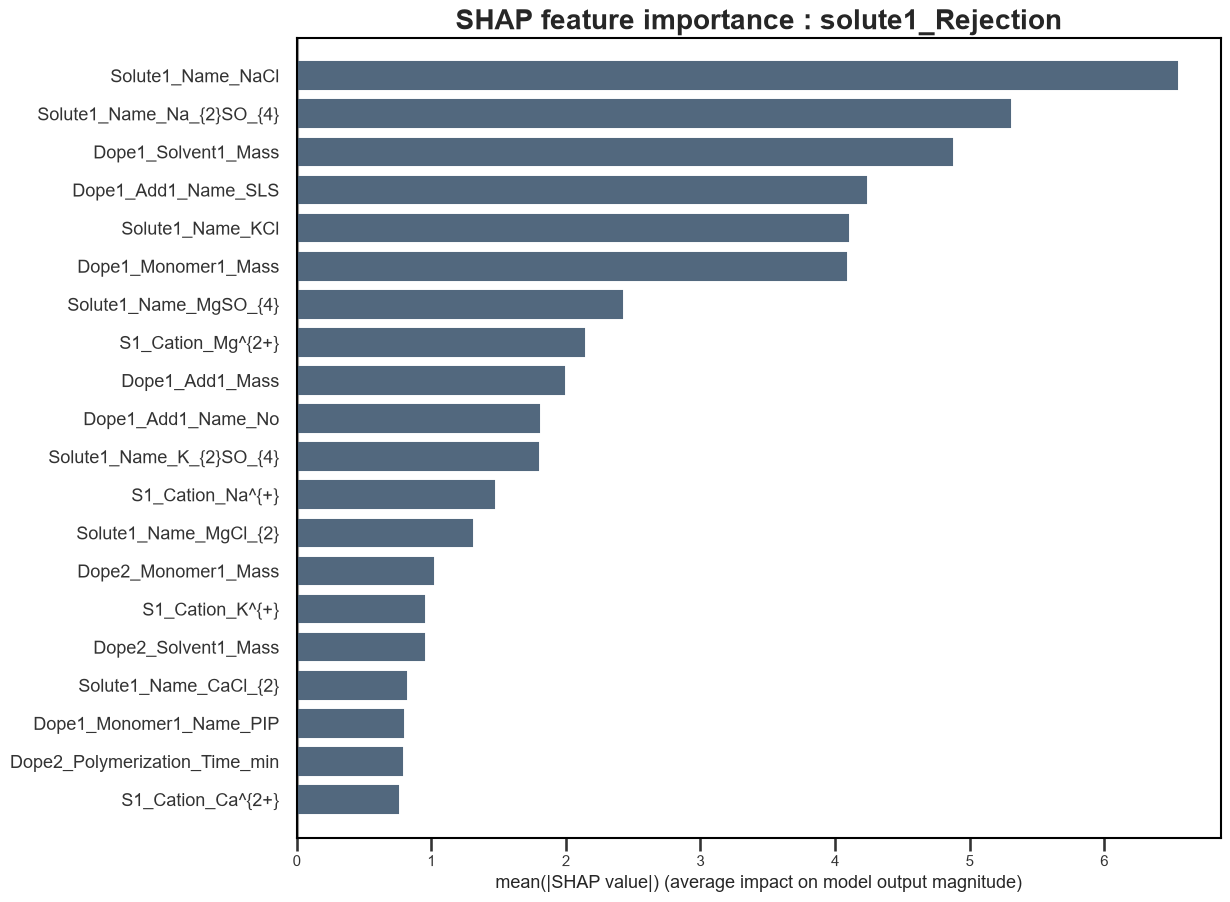

Completed SHAP analysis for 2 targets


In [14]:
import importlib
import utl_shap
from utl_fileIO import file_io

utl_shap = importlib.reload(utl_shap)

# Loop over candidate targets to compute and plot SHAP values for model interpretation
for target in candidate_targets:
    shap_values, feature_names, summary_fig, bar_fig = utl_shap.shap_explain_target(
        target=target,
        df_enriched=df_enriched,
        features_to_model=base_features,
        config=config,
        max_samples=1000,
    )

    safe_target = "".join(ch if ch.isalnum() else "_" for ch in str(target)).strip("_")
    file_io("save", "figure", FIGURES_DIR, f"shap_summary_{safe_target}.png", data=summary_fig)
    file_io("save", "figure", FIGURES_DIR, f"shap_importance_{safe_target}.png", data=bar_fig)

print(f"Completed SHAP analysis for {len(candidate_targets)} targets")

### From interpretation to scientific insight

The main value of SHAP in this workflow is that it helps connect ML outputs back to membrane design logic. If descriptors linked to monomer choice, additive loading, polymerization time, or ion properties repeatedly appear among the top-ranked contributors, that supports the view that the model is learning chemically meaningful patterns rather than arbitrary statistical artifacts.

In practice, these results should be used to prioritize hypotheses. They are most powerful when combined with membrane transport intuition and followed by targeted experiments that test whether the inferred trends hold under controlled conditions.

## Section 6. Inverse Design with Ax

After training predictive models, the next question is how to use them for design. In this notebook, Ax-based Bayesian optimization is used to search over a selected formulation space defined by fabrication variables such as `Dope1_Monomer1_Name`, `Dope1_Monomer1_Mass`, `Dope1_Add1_Name`, `Dope1_Add1_Mass`, `Dope2_Monomer1_Mass`, and `Dope2_Polymerization_Time_min`.

This transforms the predictive workflow into a generative one. Instead of only asking how a known membrane formulation will perform, the notebook asks which combinations of controllable variables are predicted to improve a chosen objective under fixed contextual assumptions.

"""
Section 5: Inverse design via Bayesian optimization (Ax)

This section:
- Defines a small search space over selected IP recipes / process variables.
- Wraps the trained model(s) in an 'oracle' that maps recipe -> performance metrics.
- Uses Ax to perform a short Bayesian optimization loop to propose improved recipes.

We use a simple scalarized objective that combines normalized water permeability
and solute1 rejection, inspired by your v13.5 inverse-design notebook.
"""

### Search space and fixed context

Inverse design requires a clear distinction between variables that are allowed to change and variables that are held fixed. In this workflow, the search space contains a focused subset of controllable interfacial polymerization descriptors, while all remaining recipe and testing conditions are supplied through a fixed parameter dictionary so that the optimization problem remains chemically meaningful.

This is a critical design choice. A search space that is too broad becomes unrealistic and difficult to interpret, whereas a focused space allows the optimizer to explore actionable experimental degrees of freedom while preserving a well-defined membrane context. Since the major goal of the inverse design is to enable the experimental validation of the membrane performance of the generated recipes and fabrication conditions, it is important to list ONLY the variables that are actionable in the lab and have a significant impact on the target properties, as identified by SHAP analysis and domain knowledge. 

It is important to note that, the search parameter space, i.e. Ax searchable + fixed parameters must be the same with the parameters space that is used to train the models.

In [15]:
import importlib
import utl_Ax

# Reload to ensure the notebook uses the latest src/utl_Ax.py changes.
utl_Ax = importlib.reload(utl_Ax)
from utl_Ax import *

In [16]:
# Define a compact search space of IP variables and conditions using config values.
# Tutorial guidance: start narrow (chemically plausible bounds), then expand after validation.

from utl_Ax import build_ax_search_space

opt_cfg = config["optimization"]

search_space_parameters = build_ax_search_space(
    opt_cfg=opt_cfg,
    choice_param_cls=ChoiceParameterConfig,
    range_param_cls=RangeParameterConfig,
)

print(f"Built search space with {len(search_space_parameters)} parameters from config")

Built search space with 6 parameters from config


### Surrogate oracle

The function `oraclefromparams` acts as the design oracle for optimization. It merges proposed parameter values with default context variables, reconstructs a one-row formulation table, applies the same feature engineering logic used during model training, and then predicts target properties with the saved ExtraTrees pipelines.

This design keeps the optimization workflow aligned with the supervised model. Because candidate formulations pass through the same descriptor construction pipeline as the training data, the inverse-design stage remains consistent with the assumptions embedded in the predictive model.

### Multi-objective scalarization

Membrane optimization is rarely single-objective. In the current notebook, the predicted values of `Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}` and `solute1_Rejection` are normalized and then combined into a single scalar objective using `normdict`, `weightdict`, and `scalarizedobjective`.

This scalarization reflects a common membrane design trade-off: improving permeability is useful only if rejection remains sufficiently high. The weighting scheme therefore encodes an explicit design preference and makes the optimization problem transparent rather than leaving the trade-off implicit.

In [17]:
# Build objective weight map used for scalarized plots and summaries.
opt_cfg = config["optimization"]

objective_weights = {}
for obj_cfg in opt_cfg["objectives"]:
    objective_name = obj_cfg["name"]
    weight = float(obj_cfg.get("weight", 1.0))
    objective_weights[objective_name] = weight

print("Loaded objective weights from config:")
for key, weight in objective_weights.items():
    print(f"  - {key}: {weight}")

Loaded objective weights from config:
  - normPureWaterPermeability: 1.0
  - solute1Rejection: 1.0


### Bayesian optimization loop

The Ax client iteratively proposes candidate formulations, evaluates them through the surrogate oracle, and updates its belief about where promising regions of the search space may lie. This sequential strategy is well suited to materials design problems because it can balance exploration of uncertain regions with exploitation of high-performing candidates.

In the context of membrane development, the optimizer should be viewed as a screening tool. Its role is to narrow the experimental search space and rank plausible candidates, not to replace fabrication and testing.

In [18]:
print(f"Optimization mode: {opt_cfg['mode']}")

client, results = run_ax_optimization(
    search_space_parameters=search_space_parameters,
    oracle_from_params=oracle_from_params,
    sobol_init=opt_cfg["sobol_init"],
    n_trials=opt_cfg["n_trials"],
    force_rebuild=True,
    save_every_trials=opt_cfg["save_checkpoint_every"],
    client_path=os.path.join(MODEL_PATH, opt_cfg["client_cache_file"]),
    config=config,
)

print(f"Optimization completed: {len(results)} trials")

[INFO 07-03 13:54:30] ax.api.client: GenerationStrategy(name='Center+Sobol+MBM:fast', nodes=[CenterGenerationNode(next_node_name='Sobol', use_existing_trials_for_initialization=True), GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')], suggested_experiment_status=ExperimentStatus.INITIALIZATION, pausing_criteria=[MaxTrialsAwaitingData(threshold=5)]), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, generator_key_override=None)], transition_criteria=None, suggested_experiment_status=ExperimentStatus.OPTIMIZATION, pausing_criteria=None)]) chosen based on user input and problem structure.
[INFO 07-03 13:54:30] ax.api.client: Generated new trial 0 with parameters {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.01005, 'Dope1_Add1_Name': 'CTAB', 'Dope1_Add1_Mass': 0.144387, 'Dope2_Monomer1_Mass': 0.001, 'Do

Optimization mode: multiobjective

Trial 0: parameters = {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.01005, 'Dope1_Add1_Name': 'CTAB', 'Dope1_Add1_Mass': 0.1443865, 'Dope2_Monomer1_Mass': 0.001, 'Dope2_Polymerization_Time_min': 10.0415}


[INFO 07-03 13:54:31] ax.api.client: Trial 0 marked COMPLETED.
[INFO 07-03 13:54:31] ax.api.client: Generated new trial 1 with parameters {'Dope1_Monomer1_Name': 'PIP', 'Dope1_Monomer1_Mass': 0.006519, 'Dope1_Add1_Mass': 0.271511, 'Dope2_Monomer1_Mass': 0.001087, 'Dope2_Polymerization_Time_min': 10.317827, 'Dope1_Add1_Name': 'CTAB'} using GenerationNode Sobol.


  metrics: {'normPureWaterPermeability': (0.25743546055349076, 0.01), 'solute1Rejection': (0.46442153961288507, 0.01)}

Trial 1: parameters = {'Dope1_Monomer1_Name': 'PIP', 'Dope1_Monomer1_Mass': 0.006519083616137505, 'Dope1_Add1_Mass': 0.27151111731195454, 'Dope2_Monomer1_Mass': 0.0010871149301528932, 'Dope2_Polymerization_Time_min': 10.317827158331871, 'Dope1_Add1_Name': 'CTAB'}


[INFO 07-03 13:54:31] ax.api.client: Trial 1 marked COMPLETED.
[INFO 07-03 13:54:31] ax.api.client: Generated new trial 2 with parameters {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.011572, 'Dope1_Add1_Mass': 0.068624, 'Dope2_Monomer1_Mass': 0.000661, 'Dope2_Polymerization_Time_min': 6.002952, 'Dope1_Add1_Name': 'SLS'} using GenerationNode Sobol.


...

  metrics: {'normPureWaterPermeability': (0.2634438838732517, 0.01), 'solute1Rejection': (0.6498282137633098, 0.01)}


[INFO 07-03 14:12:00] ax.api.client: Generated new trial 99 with parameters {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.014762, 'Dope1_Add1_Mass': 0.000393, 'Dope2_Monomer1_Mass': 0.0015, 'Dope2_Polymerization_Time_min': 0.083, 'Dope1_Add1_Name': 'Tween80'} using GenerationNode MBM.



Trial 99: parameters = {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.01476170633397004, 'Dope1_Add1_Mass': 0.000393, 'Dope2_Monomer1_Mass': 0.0015, 'Dope2_Polymerization_Time_min': 0.083, 'Dope1_Add1_Name': 'Tween80'}


[INFO 07-03 14:12:00] ax.api.client: Trial 99 marked COMPLETED.


  metrics: {'normPureWaterPermeability': (0.16691346551011982, 0.01), 'solute1Rejection': (0.4360036738442691, 0.01)}
Checkpoint saved after 100 completed trials to: c:\GITHUB_NEW\ML-MEM-Review\models\ax_client.pkl
Saved Ax client to: c:\GITHUB_NEW\ML-MEM-Review\models\ax_client.pkl
Optimization completed: 100 trials


### Interpreting the optimized candidates

The best candidate returned by the optimizer is the formulation that maximizes the scalarized objective under the current search space, weighting scheme, and fixed-context assumptions. This means the result is conditional: it is the best design according to the trained surrogate and the chosen problem definition, not a universally optimal membrane.

That distinction is important. Optimized candidates should be treated as experimentally testable hypotheses whose value lies in prioritization. If they are physically sensible and align with SHAP-derived trends, confidence in the workflow increases; if not, the result signals that either the model, the search space, or the scalarization requires refinement.

In [19]:
# Retrieve and inspect optimization recommendations from Ax.
# Works for both scalarized (single best point) and multiobjective (Pareto frontier).

import warnings
from numbers import Number

recommendations = get_optimization_recommendations(
    client=client,
    optimization_mode=opt_cfg["mode"],
    top_k=5,
)

# Tutorial next step: validate top recommendation(s) experimentally (or with held-out data),
# then append outcomes and rerun BO for closed-loop improvement.


Pareto frontier size: 17
Showing first 5 Pareto points:

Point 1:
  trial_index: 76
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.0003075650918293203
    Dope1_Add1_Name: SLS
    Dope1_Add1_Mass: 0.000393
    Dope2_Monomer1_Mass: 0.0005
    Dope2_Polymerization_Time_min: 0.083
  metrics (mean, sem):
    normPureWaterPermeability: mean=0.4348, sem=0.0000
    solute1Rejection: mean=0.8382, sem=0.0000

Point 2:
  trial_index: 85
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.0003787988994379672
    Dope1_Add1_Name: SLS
    Dope1_Add1_Mass: 0.000393
    Dope2_Monomer1_Mass: 0.0005
    Dope2_Polymerization_Time_min: 0.083
  metrics (mean, sem):
    normPureWaterPermeability: mean=0.3915, sem=0.0000
    solute1Rejection: mean=0.8485, sem=0.0000

Point 3:
  trial_index: 93
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.00794555409517421
    Dope1_Add1_Name: SLS
    Dope1_Add1_Mass: 0.000393
    Dope2_Monomer1_Mass: 0.0005
    Dope2_Po

### Inverse Design Visualization

This section converts the completed Ax trials into a compact visualization of the inverse-design search. It plots how the objective metrics evolve across trials and then visualizes the trade-off surface between normalized permeability, rejection, and the combined score, with Pareto recommendations overlaid when available.

C:\GITHUB_NEW\ML-MEM-Review\src\utl_Ax.py:1533: UserWarning:

The `rotation` parameter has not yet been implemented and is currently ignored.

C:\GITHUB_NEW\ML-MEM-Review\src\utl_Ax.py:1547: UserWarning:

The `rotation` parameter has not yet been implemented and is currently ignored.



Saved inverse design figures:
  - summary_figure
  - response_map_1_surface
  - response_map_1_contour
  - response_map_2_surface
  - response_map_2_contour


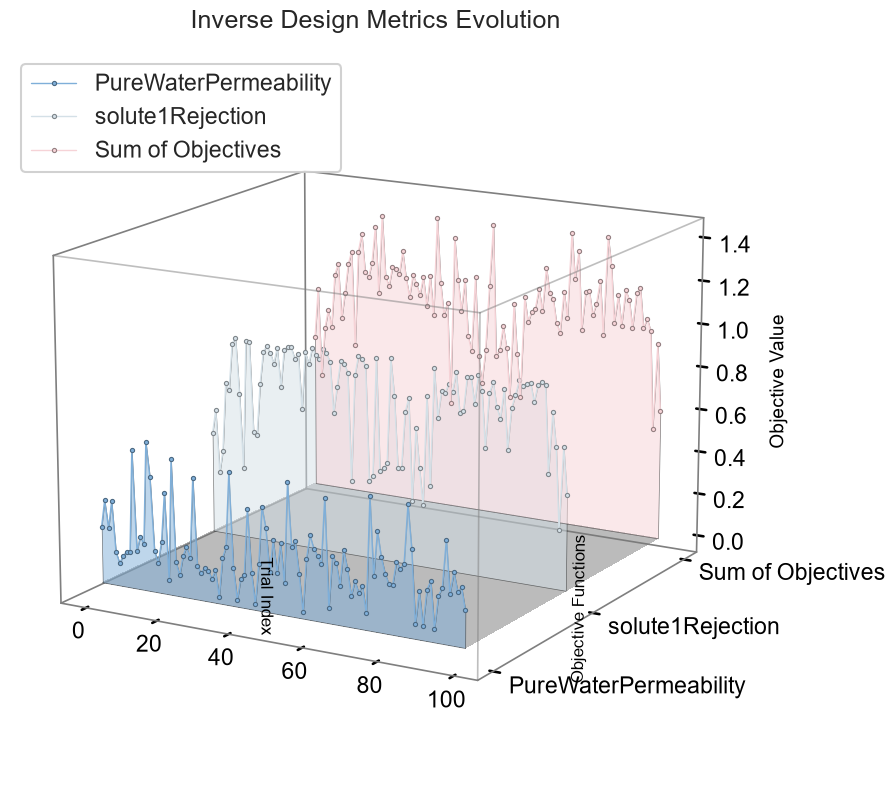

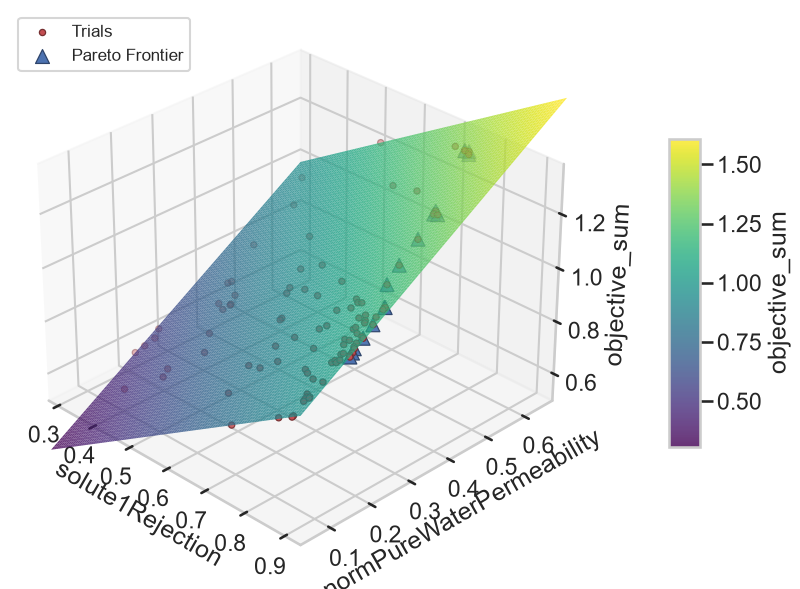

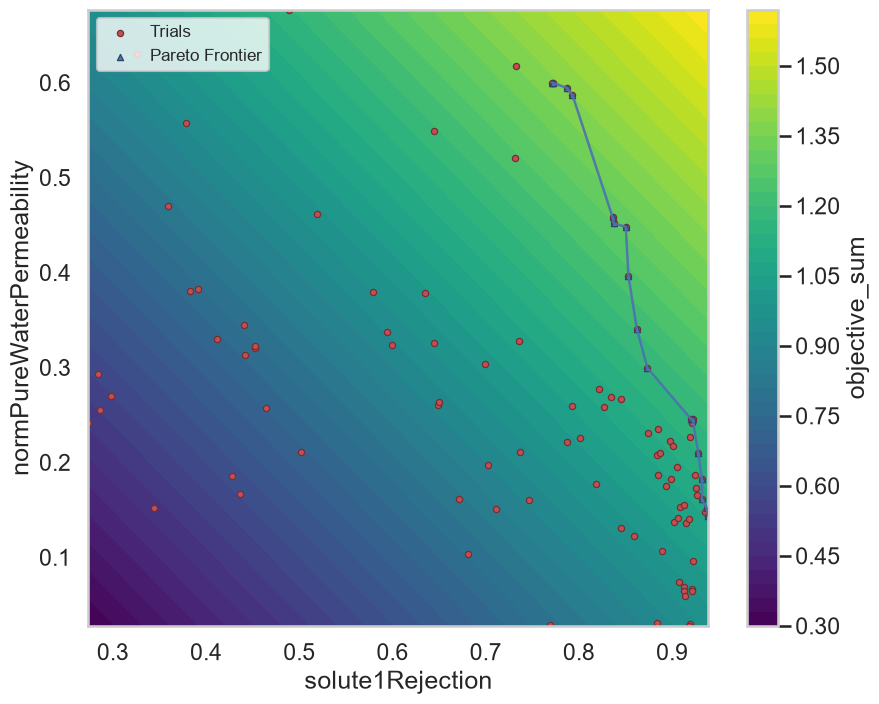

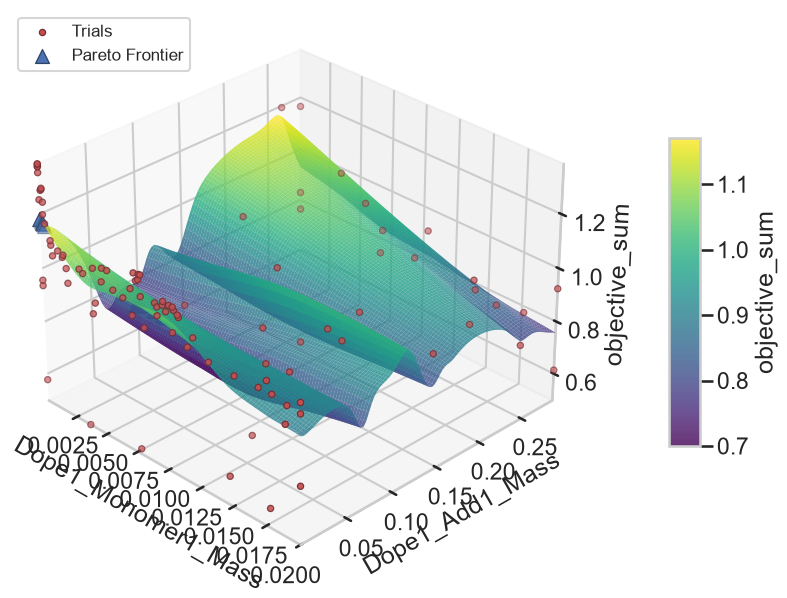

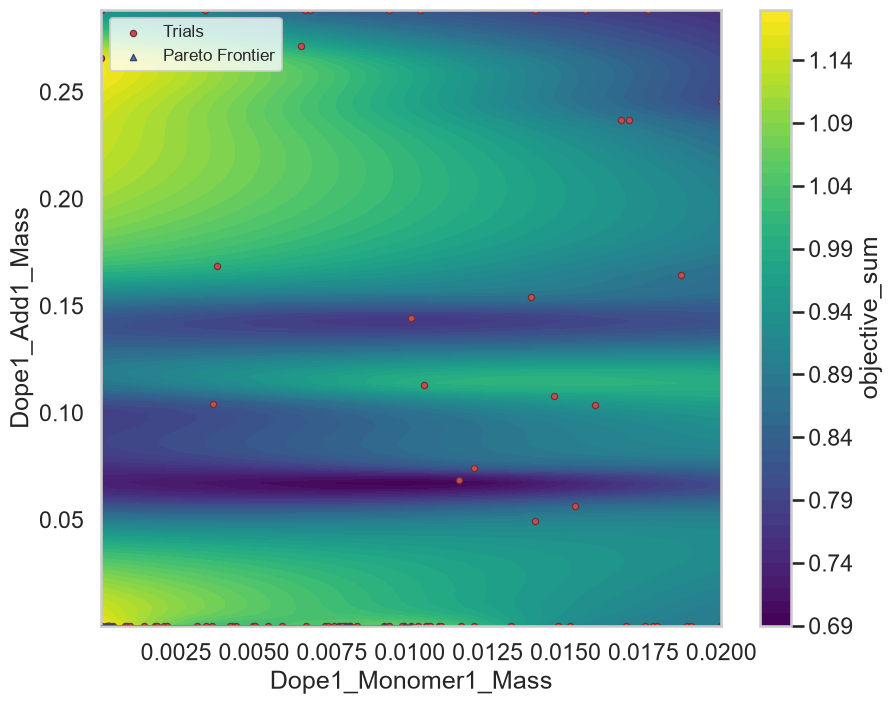

In [20]:
from importlib import reload

import utl_Ax

reload(utl_Ax)
from utl_config_loader import load_config
from utl_Ax import plot_ax_results
from utl_fileIO import file_io

config = load_config()
trial_df = results_to_dataframe(results)

viz = plot_ax_results(trial_df=trial_df, config=config, client=client)

summary_figure = viz.get("summary", {}).get("figure") if isinstance(viz.get("summary"), dict) else None
if summary_figure is None and viz.get("figures"):
    summary_figure = viz["figures"].get("summary_figure")
if summary_figure is not None:
    file_io("save", "figure", FIGURES_DIR, "inverse_design_summary.png", data=summary_figure)

for index, response_map in enumerate(viz.get("response_maps", []), start=1):
    if response_map.get("surface_figure") is not None:
        file_io(
            "save",
            "figure",
            FIGURES_DIR,
            f"response_map_{index}_surface.png",
            data=response_map["surface_figure"],
        )
    if response_map.get("contour_figure") is not None:
        file_io(
            "save",
            "figure",
            FIGURES_DIR,
            f"response_map_{index}_contour.png",
            data=response_map["contour_figure"],
        )

print("Saved inverse design figures:")
for key, fig in viz["figures"].items():
    print(f"  - {key}")
for index, _ in enumerate(viz.get("response_maps", []), start=1):
    print(f"  - response_map_{index}_surface")
    print(f"  - response_map_{index}_contour")

## Section 7. Key Takeaways

This tutorial demonstrates a full workflow for machine learning-assisted membrane development, beginning with literature-derived fabrication data and ending with interpretable predictive models and optimization-guided design suggestions. The integration of feature engineering, ExtraTrees regression, SHAP analysis, and Ax-based inverse design makes the notebook useful both as a teaching resource and as a prototype for practical membrane informatics.

The central message is that ML is most valuable when it is physically grounded. Domain-informed descriptors, careful preprocessing, transparent validation, and cautious interpretation are all necessary if membrane machine learning is to contribute meaningfully to experimental materials development.
